In [ ]:
#Karthick 24BAD055
#Importing necessary libraries

import pandas as pd
from mlxtend.frequent_patterns import apriori, association_rules
import matplotlib.pyplot as plt

   ---------------------------------------- 0.0/2.1 MB ? eta -:--:--
   --------------- ------------------------ 0.8/2.1 MB 16.4 MB/s eta 0:00:01
   ----------------------------------- ---- 1.8/2.1 MB 6.7 MB/s eta 0:00:01
   ---------------------------------------- 2.1/2.1 MB 3.7 MB/s  0:00:00


In [13]:
#Loading the dataset
df = pd.read_csv("Groceries_dataset.csv/Groceries_dataset.csv")
df.head()

,Member_number,Date,itemDescription
0,1808,21-07-2015,tropical fruit
1,2552,05-01-2015,whole milk
2,2300,19-09-2015,pip fruit
3,1187,12-12-2015,other vegetables
4,3037,01-02-2015,whole milk


In [14]:
#Grouping the items by member number to create transactions
transactions = df.groupby('Member_number')['itemDescription'].apply(list)
transactions.head()

Member_number
1000    [soda, canned beer, sausage, sausage, whole mi...
1001    [frankfurter, frankfurter, beef, sausage, whol...
1002    [tropical fruit, butter milk, butter, frozen v...
1003    [sausage, root vegetables, rolls/buns, deterge...
1004    [other vegetables, pip fruit, root vegetables,...
Name: itemDescription, dtype: object

In [15]:
#Encoding the transactions using TransactionEncoder
from mlxtend.preprocessing import TransactionEncoder

te = TransactionEncoder()
te_array = te.fit(transactions).transform(transactions)

df_encoded = pd.DataFrame(te_array, columns=te.columns_)
df_encoded.head()

,Instant food products,UHT-milk,abrasive cleaner,artif. sweetener,baby cosmetics,bags,baking powder,bathroom cleaner,beef,berries,...,turkey,vinegar,waffles,whipped/sour cream,whisky,white bread,white wine,whole milk,yogurt,zwieback
0,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,True,True,False
1,False,False,False,False,False,False,False,False,True,False,...,False,False,False,True,False,True,False,True,False,False
2,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,True,False,False
3,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,True,False,False


In [16]:
#Finding frequent itemsets using the apriori algorithm
frequent_itemsets = apriori(df_encoded, min_support=0.02, use_colnames=True)
frequent_itemsets.head()

,support,itemsets
0,0.078502,(UHT-milk)
1,0.031042,(baking powder)
2,0.119548,(beef)
3,0.079785,(berries)
4,0.062083,(beverages)


In [17]:
#Generating association rules from the frequent itemsets
rules = association_rules(frequent_itemsets, metric="confidence", min_threshold=0.3)
rules.head()

,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski
0,(UHT-milk),(other vegetables),0.078502,0.376603,0.038994,0.496732,1.318979,1.0,0.009430,1.238697,0.262440,0.093711,0.192700,0.300137
1,(UHT-milk),(rolls/buns),0.078502,0.349666,0.031042,0.395425,1.130863,1.0,0.003592,1.075687,0.125578,0.078165,0.070361,0.242100
2,(UHT-milk),(soda),0.078502,0.313494,0.027450,0.349673,1.115406,1.0,0.002840,1.055632,0.112280,0.075299,0.052700,0.218617
3,(UHT-milk),(whole milk),0.078502,0.458184,0.040534,0.516340,1.126928,1.0,0.004565,1.120242,0.122227,0.081696,0.107336,0.302403
4,(beef),(other vegetables),0.119548,0.376603,0.050795,0.424893,1.128223,1.0,0.005773,1.083966,0.129082,0.114055,0.077462,0.279885


In [18]:
#Filtering strong rules based on confidence and lift
strong_rules = rules[(rules['confidence'] > 0.5) & (rules['lift'] > 1)]
strong_rules.head()

,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski
3,(UHT-milk),(whole milk),0.078502,0.458184,0.040534,0.516340,1.126928,1.0,0.004565,1.120242,0.122227,0.081696,0.107336,0.302403
7,(beef),(whole milk),0.119548,0.458184,0.064135,0.536481,1.170886,1.0,0.009360,1.168919,0.165762,0.124875,0.144508,0.338229
22,(bottled beer),(whole milk),0.158799,0.458184,0.085428,0.537964,1.174124,1.0,0.012669,1.172672,0.176297,0.160714,0.147247,0.362207
28,(bottled water),(whole milk),0.213699,0.458184,0.112365,0.525810,1.147597,1.0,0.014452,1.142615,0.163569,0.200825,0.124815,0.385526
33,(brown bread),(whole milk),0.135967,0.458184,0.069779,0.513208,1.120091,1.0,0.007481,1.113034,0.124087,0.133072,0.101554,0.332752


In [19]:
#Displaying the top 5 strong rules sorted by lift
strong_rules.sort_values(by='lift', ascending=False).head()

,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski
856,"(soda, whole milk, sausage)",(rolls/buns),0.040021,0.349666,0.021036,0.525641,1.503264,1.0,0.007043,1.370973,0.348737,0.057063,0.270591,0.292901
806,"(yogurt, bottled water, other vegetables)",(whole milk),0.032324,0.458184,0.022063,0.682540,1.489664,1.0,0.007252,1.706721,0.339688,0.047097,0.414081,0.365346
816,"(other vegetables, whole milk, sausage)",(rolls/buns),0.050282,0.349666,0.026167,0.520408,1.488299,1.0,0.008585,1.356015,0.345462,0.070007,0.262545,0.297622
560,"(newspapers, root vegetables)",(rolls/buns),0.038738,0.349666,0.020010,0.516556,1.477283,1.0,0.006465,1.345210,0.336101,0.054318,0.256622,0.286891
800,"(soda, whole milk, bottled water)",(other vegetables),0.040021,0.376603,0.022063,0.551282,1.463827,1.0,0.006991,1.389284,0.330068,0.055917,0.280205,0.304933


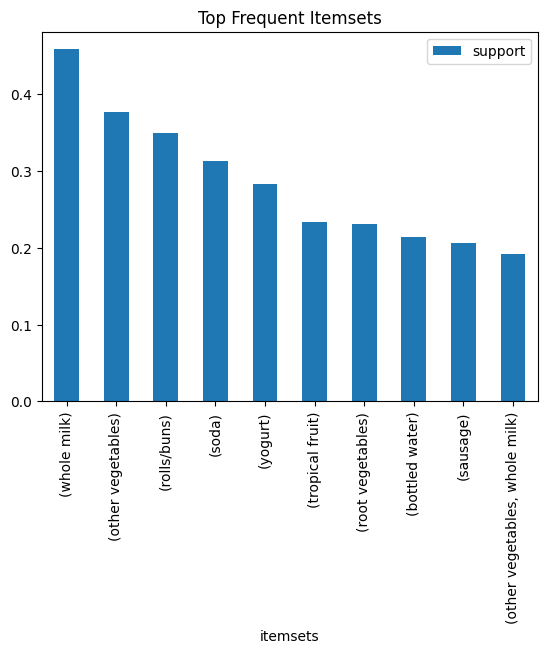

In [20]:
#Visualizing the top 10 frequent itemsets
frequent_itemsets['length'] = frequent_itemsets['itemsets'].apply(lambda x: len(x))

frequent_itemsets.sort_values(by='support', ascending=False).head(10).plot(
    x='itemsets', y='support', kind='bar'
)

plt.title("Top Frequent Itemsets")
plt.show()

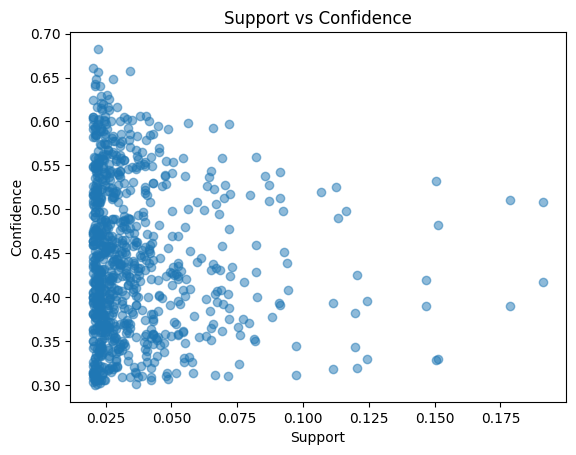

In [21]:
#Visualizing the relationship between support and confidence of the rules
plt.scatter(rules['support'], rules['confidence'], alpha=0.5)
plt.xlabel("Support")
plt.ylabel("Confidence")
plt.title("Support vs Confidence")
plt.show()

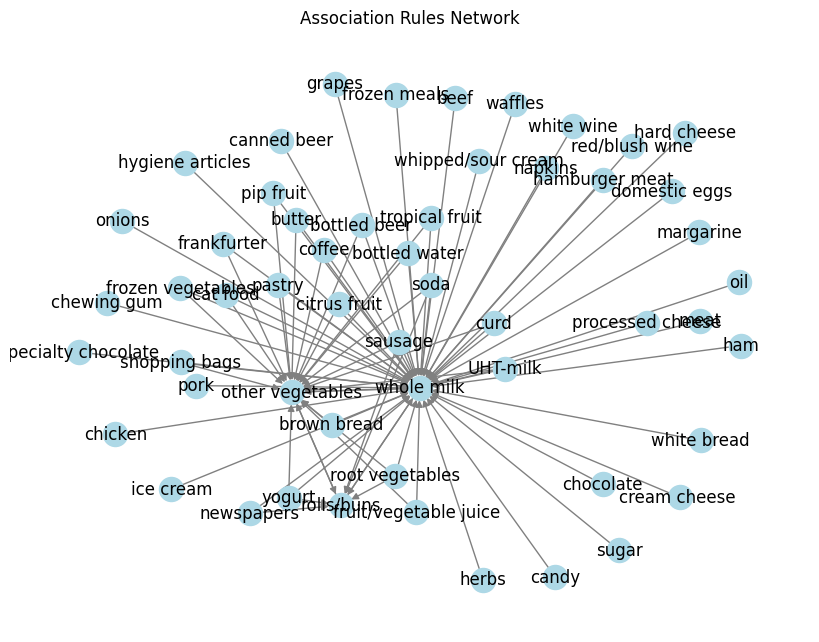

In [24]:
#Visualizing the association rules as a network graph
import networkx as nx

G = nx.DiGraph()

for _, row in strong_rules.iterrows():
    for antecedent in row['antecedents']:
        for consequent in row['consequents']:
            G.add_edge(antecedent, consequent, weight=row['lift'])

plt.figure(figsize=(8,6))
pos = nx.spring_layout(G)
nx.draw(G, pos, with_labels=True, node_color='lightblue', edge_color='gray')
plt.title("Association Rules Network")
plt.show()